<a href="https://colab.research.google.com/github/Mbogho64/Mbogho-s-week-4-course-project/blob/main/Week_4_Assignment_%7C_Exploring_the_Mathematics_of_My_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exploring the Mathematics of Slope Stability Data**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving slope_stability_dataset.csv to slope_stability_dataset.csv


In [ ]:
df = pd.read_csv("slope_stability_dataset.csv")

df.head()

,Unit Weight (kN/m³),Cohesion (kPa),Internal Friction Angle (°),Slope Angle (°),Slope Height (m),Pore Water Pressure Ratio,Reinforcement Type,Reinforcement Numeric,Factor of Safety (FS)
0,18.745401,21.813837,38.249958,41.907228,18.451042,0.847237,Drainage,3,2.613692
1,24.507143,19.981044,24.612800,32.964623,9.266800,0.494517,Geosynthetics,2,2.241626
2,22.319939,12.926926,28.665992,58.224926,10.686165,0.195466,Retaining Wall,0,1.568244
3,20.986585,32.327000,36.582016,20.948923,13.130201,0.736642,Drainage,3,3.000000
4,16.560186,26.448087,32.052234,39.392821,14.164400,0.418678,Soil Nailing,1,3.000000


**Selected Numerical Variables**

I selected four variables, that is, slope angle, cohesion, pore water pressure ratio and Factor of Safety, because they represent material strength, slope geometry, groundwater influence and slope stability. Examining their statistical properties will help characterize the dataset and investigate relationships relevant to predicting the Factor of Safety of mine and quarry slopes.

In [ ]:
variables = [
    "Cohesion (kPa)",
    "Slope Angle (°)",
    "Pore Water Pressure Ratio",
    "Factor of Safety (FS)"
]

stats = pd.DataFrame(index=variables)

stats["Mean"] = df[variables].mean()
stats["Median"] = df[variables].median()
stats["Range"] = df[variables].max() - df[variables].min()
stats["Variance"] = df[variables].var()
stats["Standard Deviation"] = df[variables].std()

stats.round(3)

,Mean,Median,Range,Variance,Standard Deviation
Cohesion (kPa),27.704,27.765,44.990,169.475,13.018
Slope Angle (°),34.936,35.002,49.989,208.795,14.450
Pore Water Pressure Ratio,0.503,0.506,1.000,0.083,0.288
Factor of Safety (FS),2.545,3.000,2.500,0.436,0.660


**Selecting two variables for covariance and correlation**

For my project, I selected:

**Input variable:** Slope Angle

**Output variable:** Factor of Safety (FS)

This pairing is useful because slope geometry is an important consideration in slope stability analysis.

In [ ]:
x = df["Slope Angle (°)"]
y = df["Factor of Safety (FS)"]

covariance = x.cov(y)
correlation = x.corr(y)

print("Covariance:", round(covariance, 4))
print("Pearson correlation:", round(correlation, 4))

Covariance: -1.1005
Pearson correlation: -0.1154


**Creating a simple plot to show the relationship between covariance and correlation:**

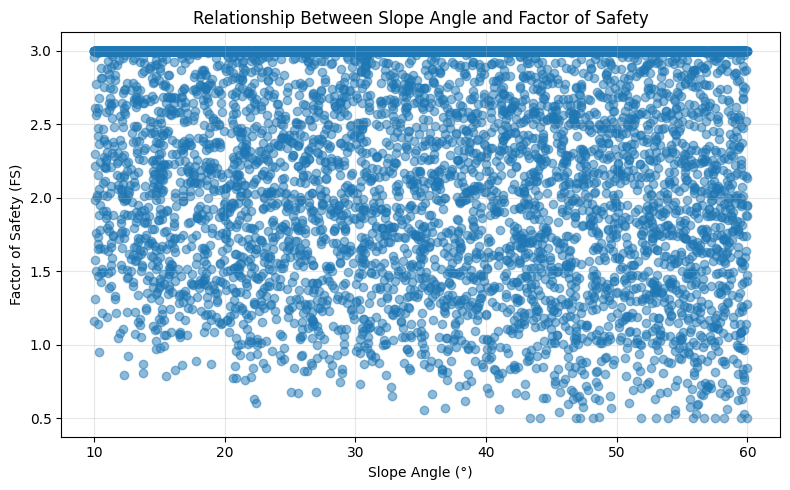

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, alpha=0.5)

plt.xlabel("Slope Angle (°)")
plt.ylabel("Factor of Safety (FS)")
plt.title("Relationship Between Slope Angle and Factor of Safety")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Explanation of the relationship shown in the plot**

The scatter plot shows the relationship between slope angle (°) on the horizontal axis and Factor of Safety (FS) on the vertical axis. The points are widely scattered across the range of slope angles, with no strong linear pattern.

The calculated Pearson correlation coefficient of −0.1154 confirms a very weak negative linear relationship. This means that higher slope angles tend to be associated with slightly lower Factors of Safety, but the association is weak.

The plot also shows that a wide range of Factor of Safety values occurs at many different slope angles. This suggests that slope angle alone does not explain most of the variation in Factor of Safety. Other variables, such as cohesion, internal friction angle, pore-water pressure and reinforcement conditions, may help explain the observed differences.

Importantly, the plot does not establish that slope angle has no engineering effect on stability. Rather, it shows that its linear association with Factor of Safety is weak in this dataset. The relationship may also depend on interactions with other variables.

**Interpretation of Descriptive Statistics**

The descriptive statistics indicate that the dataset contains considerable variation in geotechnical and slope conditions. Cohesion has a mean of 27.704 kPa and a standard deviation of 13.018 kPa, while slope angle has a mean of 34.936° and a standard deviation of 14.450°. These values indicate variation in material strength and slope steepness across the observations. The pore-water pressure ratio has a mean of 0.503 and a standard deviation of 0.288, showing variability in the represented pore-water conditions. Factor of Safety has a mean of 2.545, a median of 3.000 and a standard deviation of 0.660, indicating variation in the calculated stability of the slopes.

The Pearson correlation coefficient between slope angle and Factor of Safety is −0.1154, indicating a very weak negative linear relationship. The scatter plot supports this interpretation by showing widely dispersed observations rather than a clear linear trend. Overall, the statistics demonstrate that the dataset represents varied slope conditions and that slope angle alone has a weak linear association with Factor of Safety. Examining additional geotechnical variables together may therefore provide a more informative basis for developing a machine learning model for slope stability prediction. However, these results describe associations within the dataset and do not establish causation or demonstrate the prediction of actual slope failures.

**Interpretation of Correlation**

The Pearson correlation coefficient of −0.1154 indicates a very weak negative linear relationship between slope angle and Factor of Safety. This suggests that increasing slope angle is associated with a slight tendency for Factor of Safety to decrease, although the association is weak. Therefore, slope angle alone is insufficient to explain variations in Factor of Safety, and other geotechnical parameters should also be considered when investigating slope stability.

Correlation does not necessarily mean causation. Correlation indicates that two variables are associated, but it does not prove that changes in one variable directly cause changes in the other.

Therefore, correlation helps identify relationships worth investigating, but establishing causation requires further analysis of the relevant variables and the underlying geotechnical mechanisms.

Therefore, expressing the relationship as:

Input → Function/Model → Output

It follows that I will use slope angle variable as the input and Factror of Safety as the output


**Mathematical Representation**

Let θ represent slope angle and FS represent Factor of Safety. Their relationship can be expressed generally as:

 FS = f(θ).................................................................. (1)

A simple linear model may be written as:

 FS = β₀ + β₁θ + ε.......................................................... (2)

where β₀ is the intercept, β₁ is the slope coefficient, and ε represents unexplained variation.

The observed correlation of r = −0.1154 indicates a weak negative linear association between θ and FS. However, the correlation coefficient is not the regression coefficient β₁, and it cannot be used alone to determine the predictive equation. Other geotechnical variables may be required to improve prediction.